In [1]:
# Kaggle setup: clone repo, install libraries, find the data,
# copy anchors.json (01 output) and the Faster R-CNN results (02 output).
import os, glob, shutil, subprocess

REPO = "polluvl/hw2-video-detection"

if os.path.isdir("/kaggle/working"):
    # 1. clone the repo once per session
    if not os.path.isdir("/kaggle/working/repo"):
        r = subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO}.git", "/kaggle/working/repo"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("git clone failed (is Internet on?):\n" + r.stderr)
    # 2. install the pinned libraries
    subprocess.run(["pip", "install", "-q", "-r", "/kaggle/working/repo/requirements.txt"], check=True)
    os.chdir("/kaggle/working/repo/notebooks")

    # 3. find where Kaggle mounted the competition data
    hits = glob.glob("/kaggle/input/**/test_images.csv", recursive=True)
    if not hits:
        raise RuntimeError("Competition data not found: add it in the right panel under Input")
    os.environ["DATA_ROOT"] = os.path.dirname(hits[0])
    print("data root:", os.environ["DATA_ROOT"])

    # 4. anchors.json from the 01_eda output
    found01 = glob.glob("/kaggle/input/**/anchors.json", recursive=True)
    if not found01:
        raise RuntimeError("01 output not found: Add Input -> Your Work -> 01_eda")
    shutil.copy(found01[0], "/kaggle/working/anchors.json")
    print("copied anchors.json")

    # 5. results.csv and val predictions from the 02_faster_rcnn output (for the comparison)
    found02 = glob.glob("/kaggle/input/**/preds_val_frcnn_base.npz", recursive=True)
    if not found02:
        raise RuntimeError("02 output not found: Add Input -> Your Work -> 02_faster_rcnn")
    src = os.path.dirname(found02[0])
    shutil.copy(f"{src}/results.csv", "/kaggle/working/results.csv")
    for f in glob.glob(f"{src}/preds_val_frcnn_*.npz"):
        shutil.copy(f, "/kaggle/working/")
    print("copied 02 results from", src)

data root: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
copied anchors.json
copied 02 results from /kaggle/input/notebooks/polluvl/02-faster-rcnn


# 03 · One-stage anchor-based: RetinaNet (torchvision, ResNet-50-FPN v2, COCO-pretrained)
Same protocol as 02 (same frames, resize, augmentation, optimiser, schedule, evaluator).

Default torchvision anchors: sizes 32–512 px on P3–P7 (3 scales × ratios 0.5/1/2).
The EDA showed most objects are much smaller than 32 px after resizing, so the tuned runs use
anchors fitted on the TRAIN split (`anchors.json`, written by 01_eda).

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path("../src").resolve()))
sys.path.insert(0, str(Path("src").resolve()))
from analysis import (draw_errors, error_breakdown, recall_by_size,
                      summarise_errors, worst_frames)
from common import (SMOKE, evaluate, find_data_root, list_frames, log_result,
                    save_preds, seed_everything, work_dir)
from tv_detection import build_retinanet, predict, train_detector

# stop right away if there is no GPU (a CPU run would time out after 12 h)
assert torch.cuda.is_available(), "No GPU! Session options -> Accelerator -> GPU"
print("GPU:", torch.cuda.get_device_name(0))

DATA = find_data_root()
OUT = work_dir()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_STEP, VAL_STEP, EPOCHS = (1, 1, 1) if SMOKE else (10, 5, 5)   # 5 epochs, same as 02
train_frames = list_frames(DATA / "train", step=TRAIN_STEP)
val_frames = list_frames(DATA / "val", step=VAL_STEP)

BASE = dict(epochs=EPOCHS, batch_size=2 if SMOKE else 4, lr=0.01, num_workers=2,
            min_size=800, max_size=1333)
if SMOKE:
    BASE.update(min_size=192, max_size=320, print_every=5)

with open(OUT / "anchors.json") as f:
    anchors = json.load(f)
print("data-driven anchors:", anchors)
DATA_ANCHORS = {"anchor_sizes": anchors["retina_anchor_sizes"], "aspect_ratios": anchors["aspect_ratios"]}

GPU: Tesla T4
data-driven anchors: {'aspect_ratios': [0.505, 1.022, 2.02], 'retina_anchor_sizes': [[14.0, 17.6, 22.2], [28.0, 35.3, 44.4], [56.0, 70.6, 88.9], [112.0, 141.1, 177.8], [224.0, 282.2, 355.6]], 'frcnn_anchor_sizes': [14, 28, 56, 112, 224], 'fitted_on': 'train split only'}


## Experiments (one change at a time)
- `retina_base`     – torchvision defaults
- `retina_anchors`  – anchor sizes/ratios from the training-set box statistics
- `retina_anchors_iou` – + lower IoU thresholds for positives/negatives (0.4 / 0.3 instead of
  0.5 / 0.4): tiny boxes rarely reach IoU 0.5 with any anchor, so they get too few positives
- `retina_focal` – loss modification on top of the best of the above: focal γ = 1.5, α = 0.5
  (less down-weighting of easy examples, higher weight on the rare positives)

In [3]:
RUNS = {
    "retina_base": {},
    "retina_anchors": {**DATA_ANCHORS},
    "retina_anchors_iou": {**DATA_ANCHORS, "fg_iou": 0.4, "bg_iou": 0.3},
}

histories = {}


def run(name, changes):
    seed_everything(42)
    cfg = {**BASE, **changes}
    print(f"\n=== {name}: {changes}")
    model = build_retinanet(cfg, pretrained=not SMOKE)
    histories[name] = train_detector(model, train_frames, val_frames, cfg, DEVICE, OUT / f"{name}.pt")
    preds, ms = predict(model, val_frames, DEVICE)
    save_preds(preds, OUT / f"preds_val_{name}.npz")
    metrics = evaluate(val_frames, preds)
    log_result(name, metrics, {"family": "one-stage anchor", "ms_per_img": round(ms, 1),
                               "train_min": round(sum(h["train_min"] for h in histories[name]), 1),
                               "config": str({k: v for k, v in changes.items() if k not in DATA_ANCHORS} |
                                             ({"anchors": "data"} if "anchor_sizes" in changes else {}))})
    print(name, metrics, f"{ms:.1f} ms/img")
    del model
    torch.cuda.empty_cache()
    return metrics


for name, changes in RUNS.items():
    run(name, changes)

# focal-loss run on top of the better anchor setting
results = pd.read_csv(OUT / "results.csv")
best_prev = results[results.experiment.isin(RUNS)].sort_values("mAP").experiment.iloc[-1]
RUNS["retina_focal"] = {**RUNS[best_prev], "focal_gamma": 1.5, "focal_alpha": 0.5}
run("retina_focal", RUNS["retina_focal"])


=== retina_base: {}
Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 260MB/s]


  step 200/3055 loss 0.613 lr 0.00667
  step 400/3055 loss 0.523 lr 0.00997
  step 600/3055 loss 0.458 lr 0.00971
epoch 1: mAP 0.1450 AP50 0.2850 AP_s 0.0524 (6.0 min)
  step 800/3055 loss 0.503 lr 0.00922
  step 1000/3055 loss 0.405 lr 0.00850
  step 1200/3055 loss 0.443 lr 0.00761
epoch 2: mAP 0.1724 AP50 0.3313 AP_s 0.0610 (6.0 min)
  step 1400/3055 loss 0.486 lr 0.00659
  step 1600/3055 loss 0.511 lr 0.00549
  step 1800/3055 loss 0.342 lr 0.00436
epoch 3: mAP 0.1791 AP50 0.3459 AP_s 0.0703 (6.0 min)
  step 2000/3055 loss 0.460 lr 0.00327
  step 2200/3055 loss 0.362 lr 0.00227
  step 2400/3055 loss 0.320 lr 0.00142
epoch 4: mAP 0.1826 AP50 0.3488 AP_s 0.0739 (6.0 min)
  step 2600/3055 loss 0.395 lr 0.00075
  step 2800/3055 loss 0.480 lr 0.00031
  step 3000/3055 loss 0.331 lr 0.00011
epoch 5: mAP 0.1848 AP50 0.3527 AP_s 0.0733 (6.0 min)
retina_base {'mAP': 0.1848, 'AP50': 0.3527, 'AP75': 0.1699, 'AP_small': 0.0733, 'AP_medium': 0.1682, 'AP_large': 0.3407, 'AR': 0.3553} 185.7 ms/img



{'mAP': 0.1911,
 'AP50': 0.3664,
 'AP75': 0.1743,
 'AP_small': 0.0781,
 'AP_medium': 0.169,
 'AP_large': 0.3602,
 'AR': 0.3567}

## Curves and comparison with the tuned two-stage detector

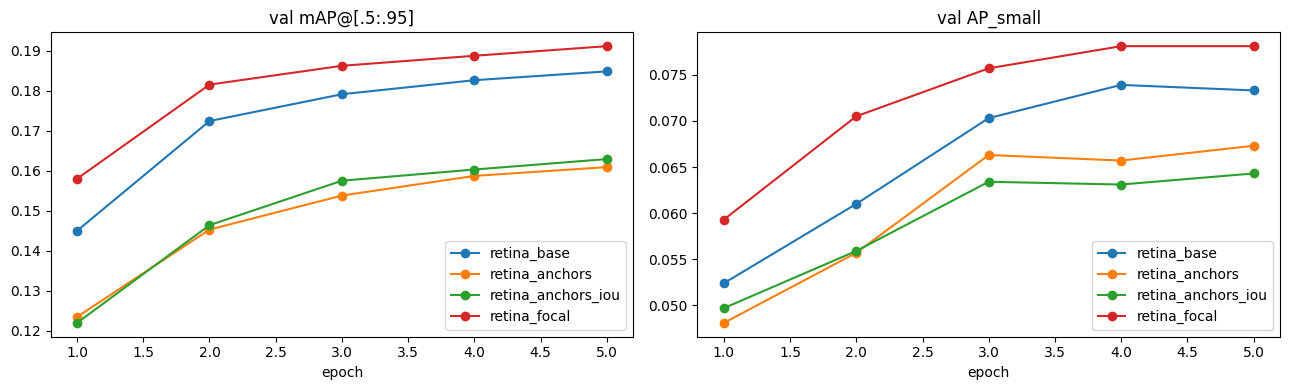

,experiment,mAP,AP50,AP_small,AP_medium,AP_large,AR,ms_per_img,train_min
0,frcnn_base,0.2384,0.4763,0.1033,0.2209,0.4263,0.4521,240.2,37.0
1,frcnn_giou,0.2276,0.4545,0.1015,0.2131,0.4171,0.4503,240.3,37.0
2,frcnn_roi,0.2203,0.4480,0.1059,0.2097,0.4040,0.4364,240.2,33.6
3,retina_base,0.1848,0.3527,0.0733,0.1682,0.3407,0.3553,185.7,30.1
4,retina_anchors,0.1609,0.3562,0.0673,0.1526,0.2904,0.3814,185.6,30.1
5,retina_anchors_iou,0.1629,0.3548,0.0643,0.1520,0.2895,0.3528,185.6,30.1
6,retina_focal,0.1911,0.3664,0.0781,0.1690,0.3602,0.3567,185.0,30.2


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    h = pd.DataFrame(h)
    axes[0].plot(h.epoch, h.mAP, marker="o", label=name)
    axes[1].plot(h.epoch, h.AP_small, marker="o", label=name)
axes[0].set_title("val mAP@[.5:.95]")
axes[1].set_title("val AP_small")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT / "figures_retina_curves.png", dpi=120)
plt.show()

results = pd.read_csv(OUT / "results.csv")
cols = ["experiment", "mAP", "AP50", "AP_small", "AP_medium", "AP_large", "AR", "ms_per_img", "train_min"]
results[results.experiment.str.startswith(("frcnn", "retina"))][cols]

## Recall by size and error types: best RetinaNet vs best Faster R-CNN

In [5]:
from common import load_preds

best_retina = results[results.experiment.str.startswith("retina")].sort_values("mAP").experiment.iloc[-1]
best_frcnn = results[results.experiment.str.startswith("frcnn")].sort_values("mAP").experiment.iloc[-1]
table = {}
for name in [best_frcnn, best_retina]:
    p = load_preds(OUT / f"preds_val_{name}.npz")
    gts, fps = error_breakdown(val_frames, p, score_thr=0.3)
    table[name] = recall_by_size(gts)
    _, _, fp_types = summarise_errors(gts, fps)
    print(name, "false positives:", fp_types.to_dict())
pd.DataFrame(table)

frcnn_base false positives: {'background': 2995, 'poor_loc': 2473, 'wrong_class': 2464, 'duplicate': 108}
retina_focal false positives: {'wrong_class': 4468, 'background': 4339, 'poor_loc': 3797, 'duplicate': 598}


,frcnn_base,retina_focal
size_bin,,
tiny <16,0.117,0.065
small 16-32,0.451,0.409
medium 32-96,0.629,0.591
large >96,0.825,0.865


TODO (your analysis):
- did the data-driven anchors help, and for which sizes?
- what problems come from removing the proposal stage (foreground/background imbalance over
  ~100k+ anchors per image, no RoI re-sampling, no second refinement) and how focal loss /
  IoU thresholds address them — support with the numbers above.